This notebook analyses the data previously published by [Thévenot et al. (2015)](https://doi.org/10.1021/acs.jproteome.5b00354) based on the work described in [Mendez et al. (2019)](https://doi.org/10.1007/s11306-019-1612-4) using a partial least squares regression (PLS) and a linear artificial neural network (ANN) classifier.

This notebook was written by Mauriz Lichtenstein

# 1. Import packages

In [2]:
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.cross_decomposition import PLSRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, make_scorer

# 2. Load data

In [4]:
raw_url = 'https://raw.githubusercontent.com/CIMCB/MetabComparisonBinaryML/master/notebooks/data/MTBLS404.xlsx'

if not os.path.exists('../data/MTBLS404.xlsx'):
    # Download the file
    response = requests.get(raw_url)
    with open('../data/MTBLS404.xlsx', 'wb') as f:
        f.write(response.content)

DataTable = pd.read_excel('../data/MTBLS404.xlsx', sheet_name='Data')
PeakTable = pd.read_excel('../data/MTBLS404.xlsx', sheet_name='Peak')

print(DataTable.head())
print(PeakTable.head())

   Idx       SampleID  Class     Sex        M1       M2       M3         M4  \
0    1  HU_neg_011_b2      1    Male   33714.0   256102   256102  1120354.0   
1    2  HU_neg_014_b2      0  Female   99843.0   309401   309401  1398006.0   
2    3  HU_neg_015_b2      1    Male   88831.0   446367   446367  2525989.0   
3    4     HU_neg_017      1    Male    3193.0   202963   202963  1328899.0   
4    5     HU_neg_018      1    Male  148709.0  1141194  1141194  2213443.0   

        M5        M6  ...       M111      M112      M113       M114      M115  \
0  2410036  11549910  ...   521907.0  171324.0  127231.0  5112492.0  28514582   
1  6026857   5257922  ...  1833652.0   12438.0  979416.0  1895831.0  20498119   
2  9245374  17608775  ...   892482.0  176146.0  223930.0   627359.0  17310020   
3  3085203  10657431  ...   387400.0   84087.0  371298.0   571396.0   9114737   
4  7049050  13044183  ...   576816.0  451233.0  602941.0  3336582.0  19810476   

       M116    M117      M118       M1

/opt/homebrew/Caskroom/miniconda/base/envs/mlails/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/opt/homebrew/Caskroom/miniconda/base/envs/mlails/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


# 3. Clean data

In [5]:
# Extract PeakList
PeakList = PeakTable['Name']

# Count the number of missing values in each column
missing_values = DataTable[PeakList].isnull().sum()
print(f'The columns with missing values are: {missing_values[missing_values > 0].to_list()}')

The columns with missing values are: []


We don't need to worry about imputing values or calculating the log(0), since every peak in the datasets has a value != 0.

# 4. train test splits

In [6]:
# Select Subset of Data
DataTable2 = DataTable[(DataTable.Class == 1) | (DataTable.Class == 0)]

# Create a Binary Y Vector 
Y = DataTable2['Class'].values
X = DataTable2[PeakList].copy()

# Split Data into Train (2/3) and Test (1/3)
XTrain, XTest, YTrain, YTest = train_test_split(X, Y, test_size=1/3, stratify=Y, random_state=40)

preprocessor = Pipeline([
    ('log', FunctionTransformer(np.log, validate=True)),   # log1p to avoid log(0)
    ('scaler', StandardScaler()),
])

Xtrain_proc = preprocessor.fit_transform(XTrain)
Xtest_proc = preprocessor.transform(XTest)

# 5. Hyperparameter optimisation

## PLS-Regression

In [7]:
# Custom scorer that uses regression outputs directly
def pls_auc(y_true, y_pred):
    return roc_auc_score(y_true, y_pred)

# Wrap it for GridSearchCV
auc_scorer = make_scorer(pls_auc)

param_grid = {
    'n_components': [1, 2, 3, 4, 5, 6]
}

pls = PLSRegression()

cv_pls = GridSearchCV(
    estimator=PLSRegression(),
    param_grid={'n_components': [1, 2, 3, 4, 5, 6]},
    cv=StratifiedKFold(n_splits=5),
    scoring=auc_scorer,
    return_train_score=True
)
cv_pls.fit(Xtrain_proc, YTrain)
print(f"Best n_components: {cv_pls.best_params_['n_components']}")

Best n_components: 3


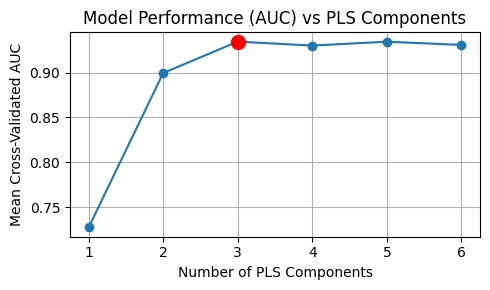

In [9]:
# Extract AUC scores and n_components
mean_test_scores = cv_pls.cv_results_['mean_test_score']
n_components_list = cv_pls.cv_results_['param_n_components'].data

# Plot
plt.figure(figsize=(5, 3))
plt.plot(n_components_list, mean_test_scores, marker='o', linestyle='-')
plt.plot(cv_pls.best_params_['n_components'], cv_pls.best_score_, marker='o', markersize=10, color='red', label='Best n_components')
plt.xlabel('Number of PLS Components')
plt.ylabel('Mean Cross-Validated AUC')
plt.title('Model Performance (AUC) vs PLS Components')
plt.grid(True)
plt.tight_layout()
plt.show()

## linear ANN

In [15]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# Suppress only convergence warnings
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Parameter grid - first sweep
param_grid_1 = {
    'learning_rate_init': [0.001, 0.005, 0.01, 0.05, 0.1, 1, 10],
    'hidden_layer_sizes': [(n,) for n in [2, 3, 4, 5, 6]],
}

# First grid search
mlp = MLPClassifier(
    activation='logistic',  # sigmoid
    solver='sgd',
    max_iter=400,
    momentum=0.5,
    learning_rate='constant',
    alpha=0.0,  # no L2 decay
    random_state=42
)

cv_nn = GridSearchCV(
    estimator=mlp,
    param_grid=param_grid_1,
    scoring='roc_auc',
    cv=StratifiedKFold(n_splits=5),
    return_train_score=True,
    verbose=0
)

cv_nn.fit(Xtrain_proc, YTrain)

print(f"Best learning_rate_init: {cv_nn.best_params_['learning_rate_init']}")
print(f"Best hidden_layer_sizes: {cv_nn.best_params_['hidden_layer_sizes']}")
print(f"Best AUC: {cv_nn.best_score_}")

Best learning_rate_init: 1
Best hidden_layer_sizes: (5,)
Best AUC: 0.9428571428571428


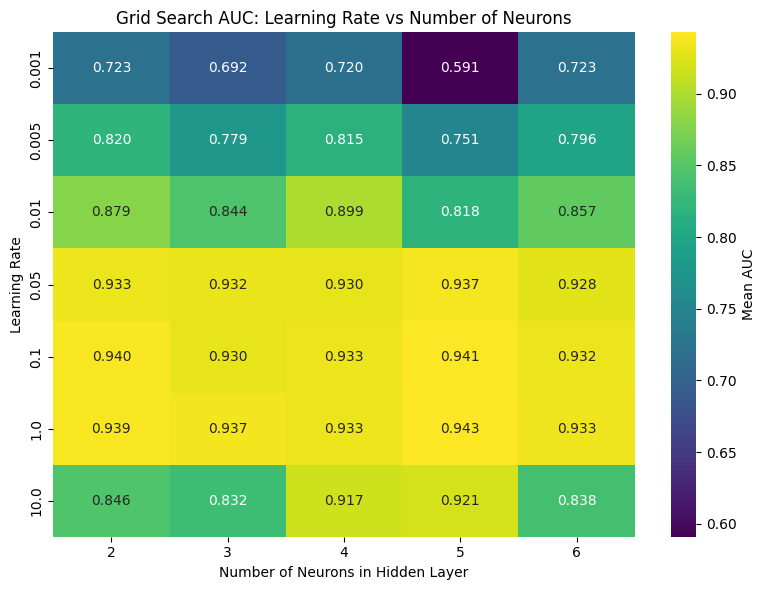

In [16]:
results = pd.DataFrame(cv_nn.cv_results_)

# Extract learning rate and number of neurons from parameters
results['learning_rate'] = results['param_learning_rate_init']
results['n_neurons'] = results['param_hidden_layer_sizes'].apply(lambda x: x[0])

# Pivot to create a matrix: rows = learning rates, columns = n_neurons
pivot_table = results.pivot_table(
    values='mean_test_score',
    index='learning_rate',
    columns='n_neurons'
)

plt.figure(figsize=(8, 6))
sns.heatmap(pivot_table, annot=True, fmt=".3f", cmap="viridis", cbar_kws={'label': 'Mean AUC'})
plt.title("Grid Search AUC: Learning Rate vs Number of Neurons")
plt.xlabel("Number of Neurons in Hidden Layer")
plt.ylabel("Learning Rate")
plt.tight_layout()
plt.show()

# 6. Build model

## PLS-DA

In [17]:
best_pls = PLSRegression(n_components=cv_pls.best_params_['n_components'])
best_pls.fit(Xtrain_proc, YTrain)

# Predict (continuous scores)
y_train_pred = best_pls.predict(Xtrain_proc).ravel()
y_test_pred = best_pls.predict(Xtest_proc).ravel()

# Convert to class predictions (threshold = 0.5)
y_train_cls = (y_train_pred >= 0.5).astype(int)
y_test_cls = (y_test_pred >= 0.5).astype(int)

# Evaluate
print("Train Accuracy:", accuracy_score(YTrain, y_train_cls))
print("Train ROC AUC:", roc_auc_score(YTrain, y_train_pred))
print("Test Accuracy:", accuracy_score(YTest, y_test_cls))
print("Test ROC AUC:", roc_auc_score(YTest, y_test_pred))

Train Accuracy: 0.9590163934426229
Train ROC AUC: 0.9810040705563093
Test Accuracy: 0.8387096774193549
Test ROC AUC: 0.921218487394958


## linear ANN

In [ ]:
# Best hyperparameters
best_nn = cv_nn.best_params_
print("Best Parameters:", best_nn)

# Final model
final_nn = MLPClassifier(
    activation='logistic',
    solver='sgd',
    learning_rate_init=best_nn['learning_rate_init'],
    hidden_layer_sizes=best_nn['hidden_layer_sizes'],
    momentum=0.5,
    learning_rate='constant',
    alpha=0.0,
    max_iter=400,
    random_state=42
)

final_nn.fit(Xtrain_proc, YTrain)

# Predict
YTrain_pred_prob = final_nn.predict_proba(Xtrain_proc)[:, 1]
YTest_pred_prob = final_nn.predict_proba(Xtest_proc)[:, 1]

# Threshold at 0.5
YTrain_pred = (YTrain_pred_prob >= 0.5).astype(int)
YTest_pred = (YTest_pred_prob >= 0.5).astype(int)

# Evaluation
print("Train AUC:", roc_auc_score(YTrain, YTrain_pred_prob))
print("Test AUC:", roc_auc_score(YTest, YTest_pred_prob))

Best Parameters: {'hidden_layer_sizes': (5,), 'learning_rate_init': 1}
Train AUC: 1.0
Test AUC: 0.9527310924369747


I used 5 neurons in the hidden layer, while Mendez et al. used 4

# 7. Extract important features

## PLS-DA

In [20]:
pls_coeffs = best_pls.coef_.ravel()  # shape (n_features,)

# Get top 3 features by absolute weight
pls_top_idx = np.argsort(np.abs(pls_coeffs))[::-1][:5]
pls_top_features = [(PeakList[i], PeakTable['Label'][i], pls_coeffs[i]) for i in pls_top_idx]

print("Top 5 PLS features:")
for name, label, coef in pls_top_features:
    print(f"{name}, {label}: coefficient = {coef:.4f}")

Top 5 PLS features:
M91, p-Anisic acid: coefficient = -0.0805
M112, Testosterone glucuronide: coefficient = 0.0596
M111, Taurine: coefficient = 0.0579
M90, Oxoglutaric acid: coefficient = -0.0573
M92, Pantothenic acid: coefficient = -0.0551


## ANN

In [21]:
# Extract weights from the MLPClassifier
input_weights = final_nn.coefs_[0]      # shape: (n_features, n_hidden)
output_weights = final_nn.coefs_[1]     # shape: (n_hidden,)

# Compute feature importance: dot product (or element-wise mult + sum)
importance_scores = np.abs(input_weights @ output_weights)  # shape: (n_features,)

# Top 3 features
ann_top_idx = np.argsort(importance_scores, axis=0)[::-1][:5].flatten()
ann_top_features = [(PeakList[i], PeakTable['Label'][i], importance_scores[i][0]) for i in ann_top_idx]

print("Top 5 ANN features:")
for name, label, coef in ann_top_features:
    print(f"{name}, {label}: coefficient = {coef:.4f}")

Top 5 ANN features:
M112, Testosterone glucuronide: coefficient = 11.5299
M92, Pantothenic acid: coefficient = 9.9659
M90, Oxoglutaric acid: coefficient = 8.5486
M111, Taurine: coefficient = 7.8483
M91, p-Anisic acid: coefficient = 7.2062
